# 07　4月：17条件内で残る特徴と、送電・供給範囲の診断

固定R（PV・風力・原子力実績）と既存の名参照調整供給除去を維持します。正式RSI、実際の企業不可欠性、最終baselineではありません。

見る順番：①17条件の全時刻 → ②停止ペア → ③上下包絡の解除 → ④供給の数値条件と記録保留 → ⑤価格を使わず選んだ代表時刻。

詳細は `reports/23_april_constraint_diagnosis/README.md` です。

In [1]:
import sys
from pathlib import Path

import pandas as pd
from IPython.display import Image, display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
OUT = ROOT / "data/interim/occto/april_constraint_diagnosis/20261027_constraints_v2"
REPORT = ROOT / "reports/23_april_constraint_diagnosis"
QA = REPORT / "qa"


def show(name):
    display(Image(filename=str(REPORT / "figures" / (name + ".png"))))


print("保存版:", OUT.name)
print("全時刻の分母は各法人1,440コマ。元の17供給条件は変更しません。")

保存版: 20261027_constraints_v2
全時刻の分母は各法人1,440コマ。元の17供給条件は変更しません。


## 1．17条件で判定が一致する時刻と、比較範囲が変わる時刻

全法人時から不成立の条件を企業除去効果へ数えません。灰色242コマは、全17条件とも全法人不成立10コマ＋条件によって成立判定が変わる232コマです。その中の比較可能条件の変化flagも別表へ保持します。

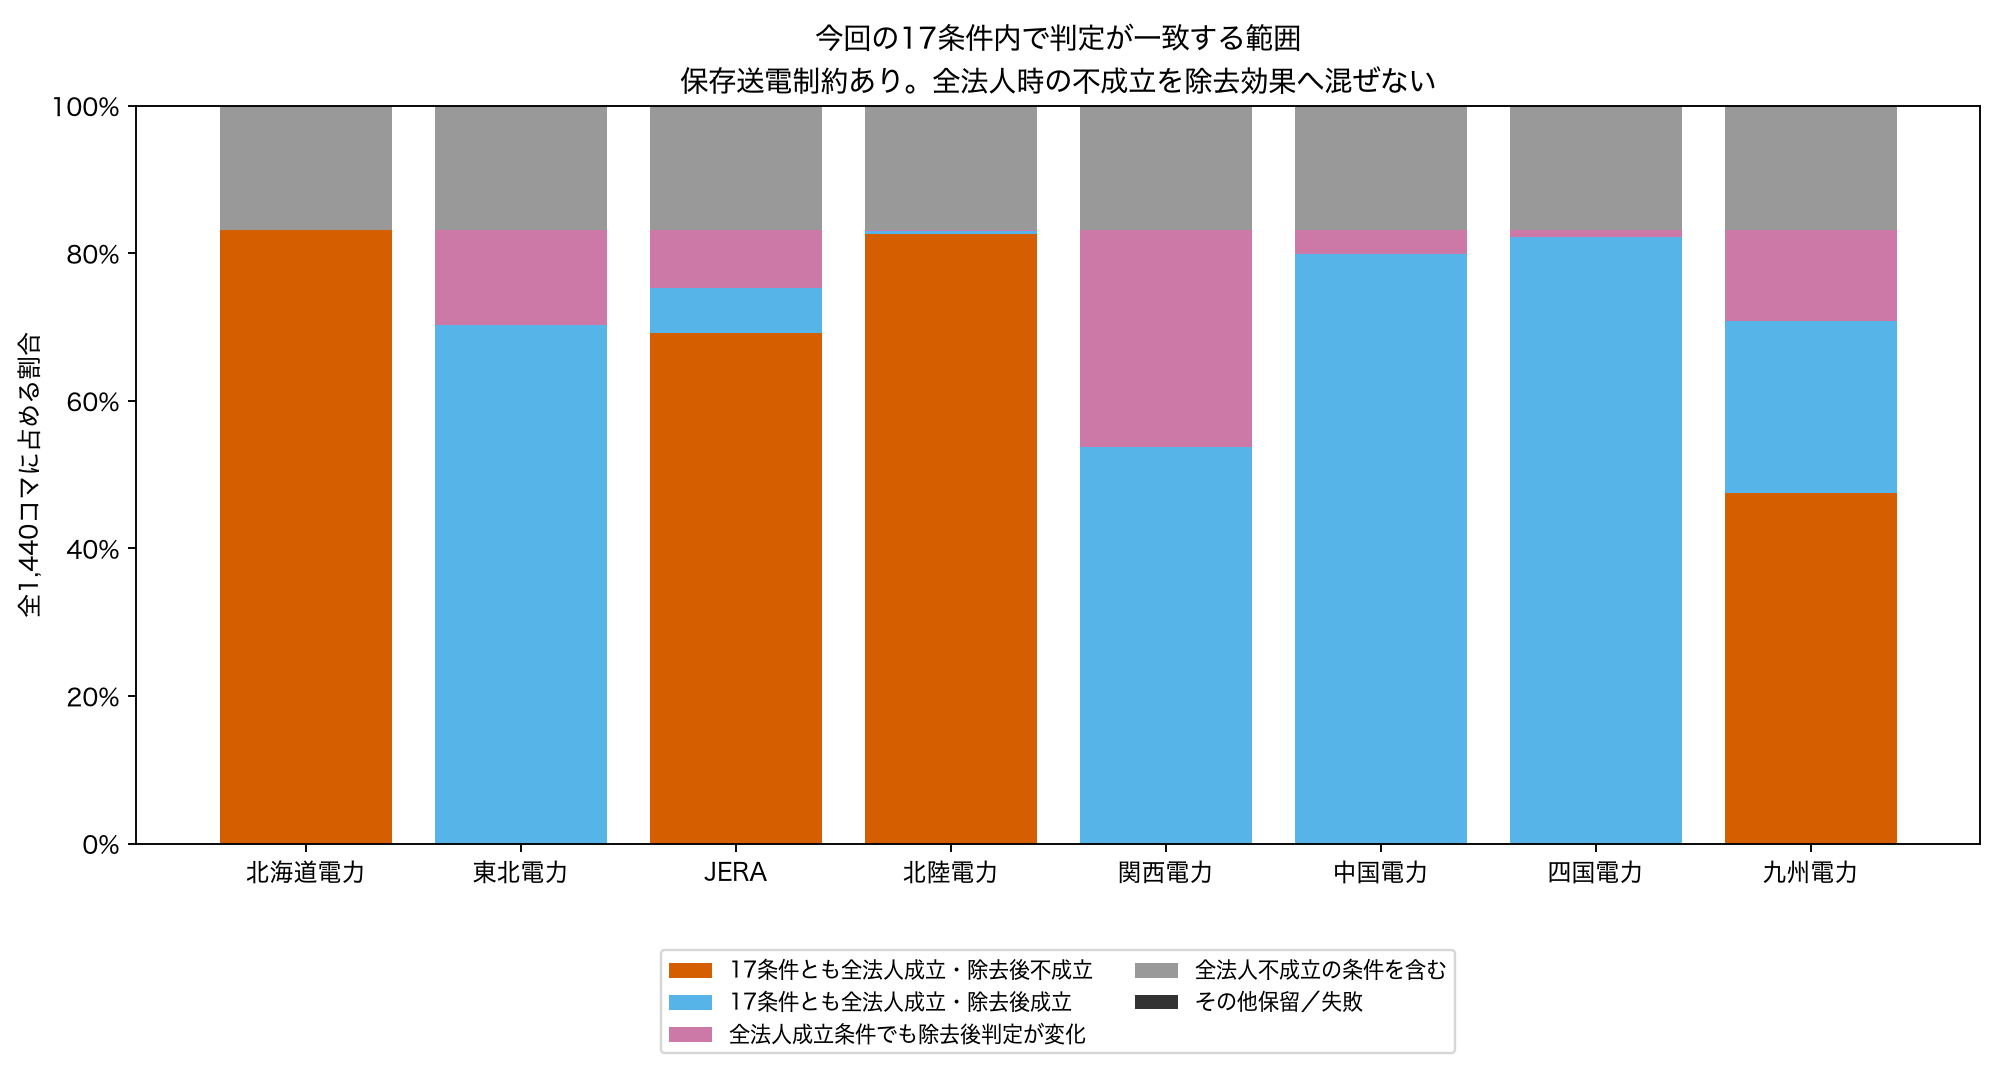

,network_scenario,entity_code,consistency_state,time_keys
0,no_transmission_bounds,chugoku,all17_base_feasible_removed_feasible,1278
1,no_transmission_bounds,chugoku,baseline_scope_differs,69
2,no_transmission_bounds,chugoku,removed_varies_among_baseline_feasible,93
3,no_transmission_bounds,hokkaido,all17_base_feasible_removed_feasible,1311
4,no_transmission_bounds,hokkaido,baseline_scope_differs,69
5,no_transmission_bounds,hokkaido,removed_varies_among_baseline_feasible,60
6,no_transmission_bounds,hokuriku,all17_base_feasible_removed_feasible,1307
7,no_transmission_bounds,hokuriku,baseline_scope_differs,69
8,no_transmission_bounds,hokuriku,removed_varies_among_baseline_feasible,64
9,no_transmission_bounds,jera,all17_base_feasible_removed_feasible,605


,network_scenario,entity_code,time_keys,comparable_variation_times,all17_baseline_infeasible
0,no_transmission_bounds,chugoku,1440,134,0
1,no_transmission_bounds,hokkaido,1440,92,0
2,no_transmission_bounds,hokuriku,1440,96,0
3,no_transmission_bounds,jera,1440,830,0
4,no_transmission_bounds,kansai,1440,248,0
5,no_transmission_bounds,kyushu,1440,165,0
6,no_transmission_bounds,shikoku,1440,60,0
7,no_transmission_bounds,tohoku,1440,132,0
8,saved_plan_constraints,chugoku,1440,82,10
9,saved_plan_constraints,hokkaido,1440,0,10


In [2]:
show("02_condition_consistency")
display(pd.read_csv(QA / "condition_consistency_counts.csv"))
display(pd.read_csv(QA / "overlapping_consistency_flags.csv"))

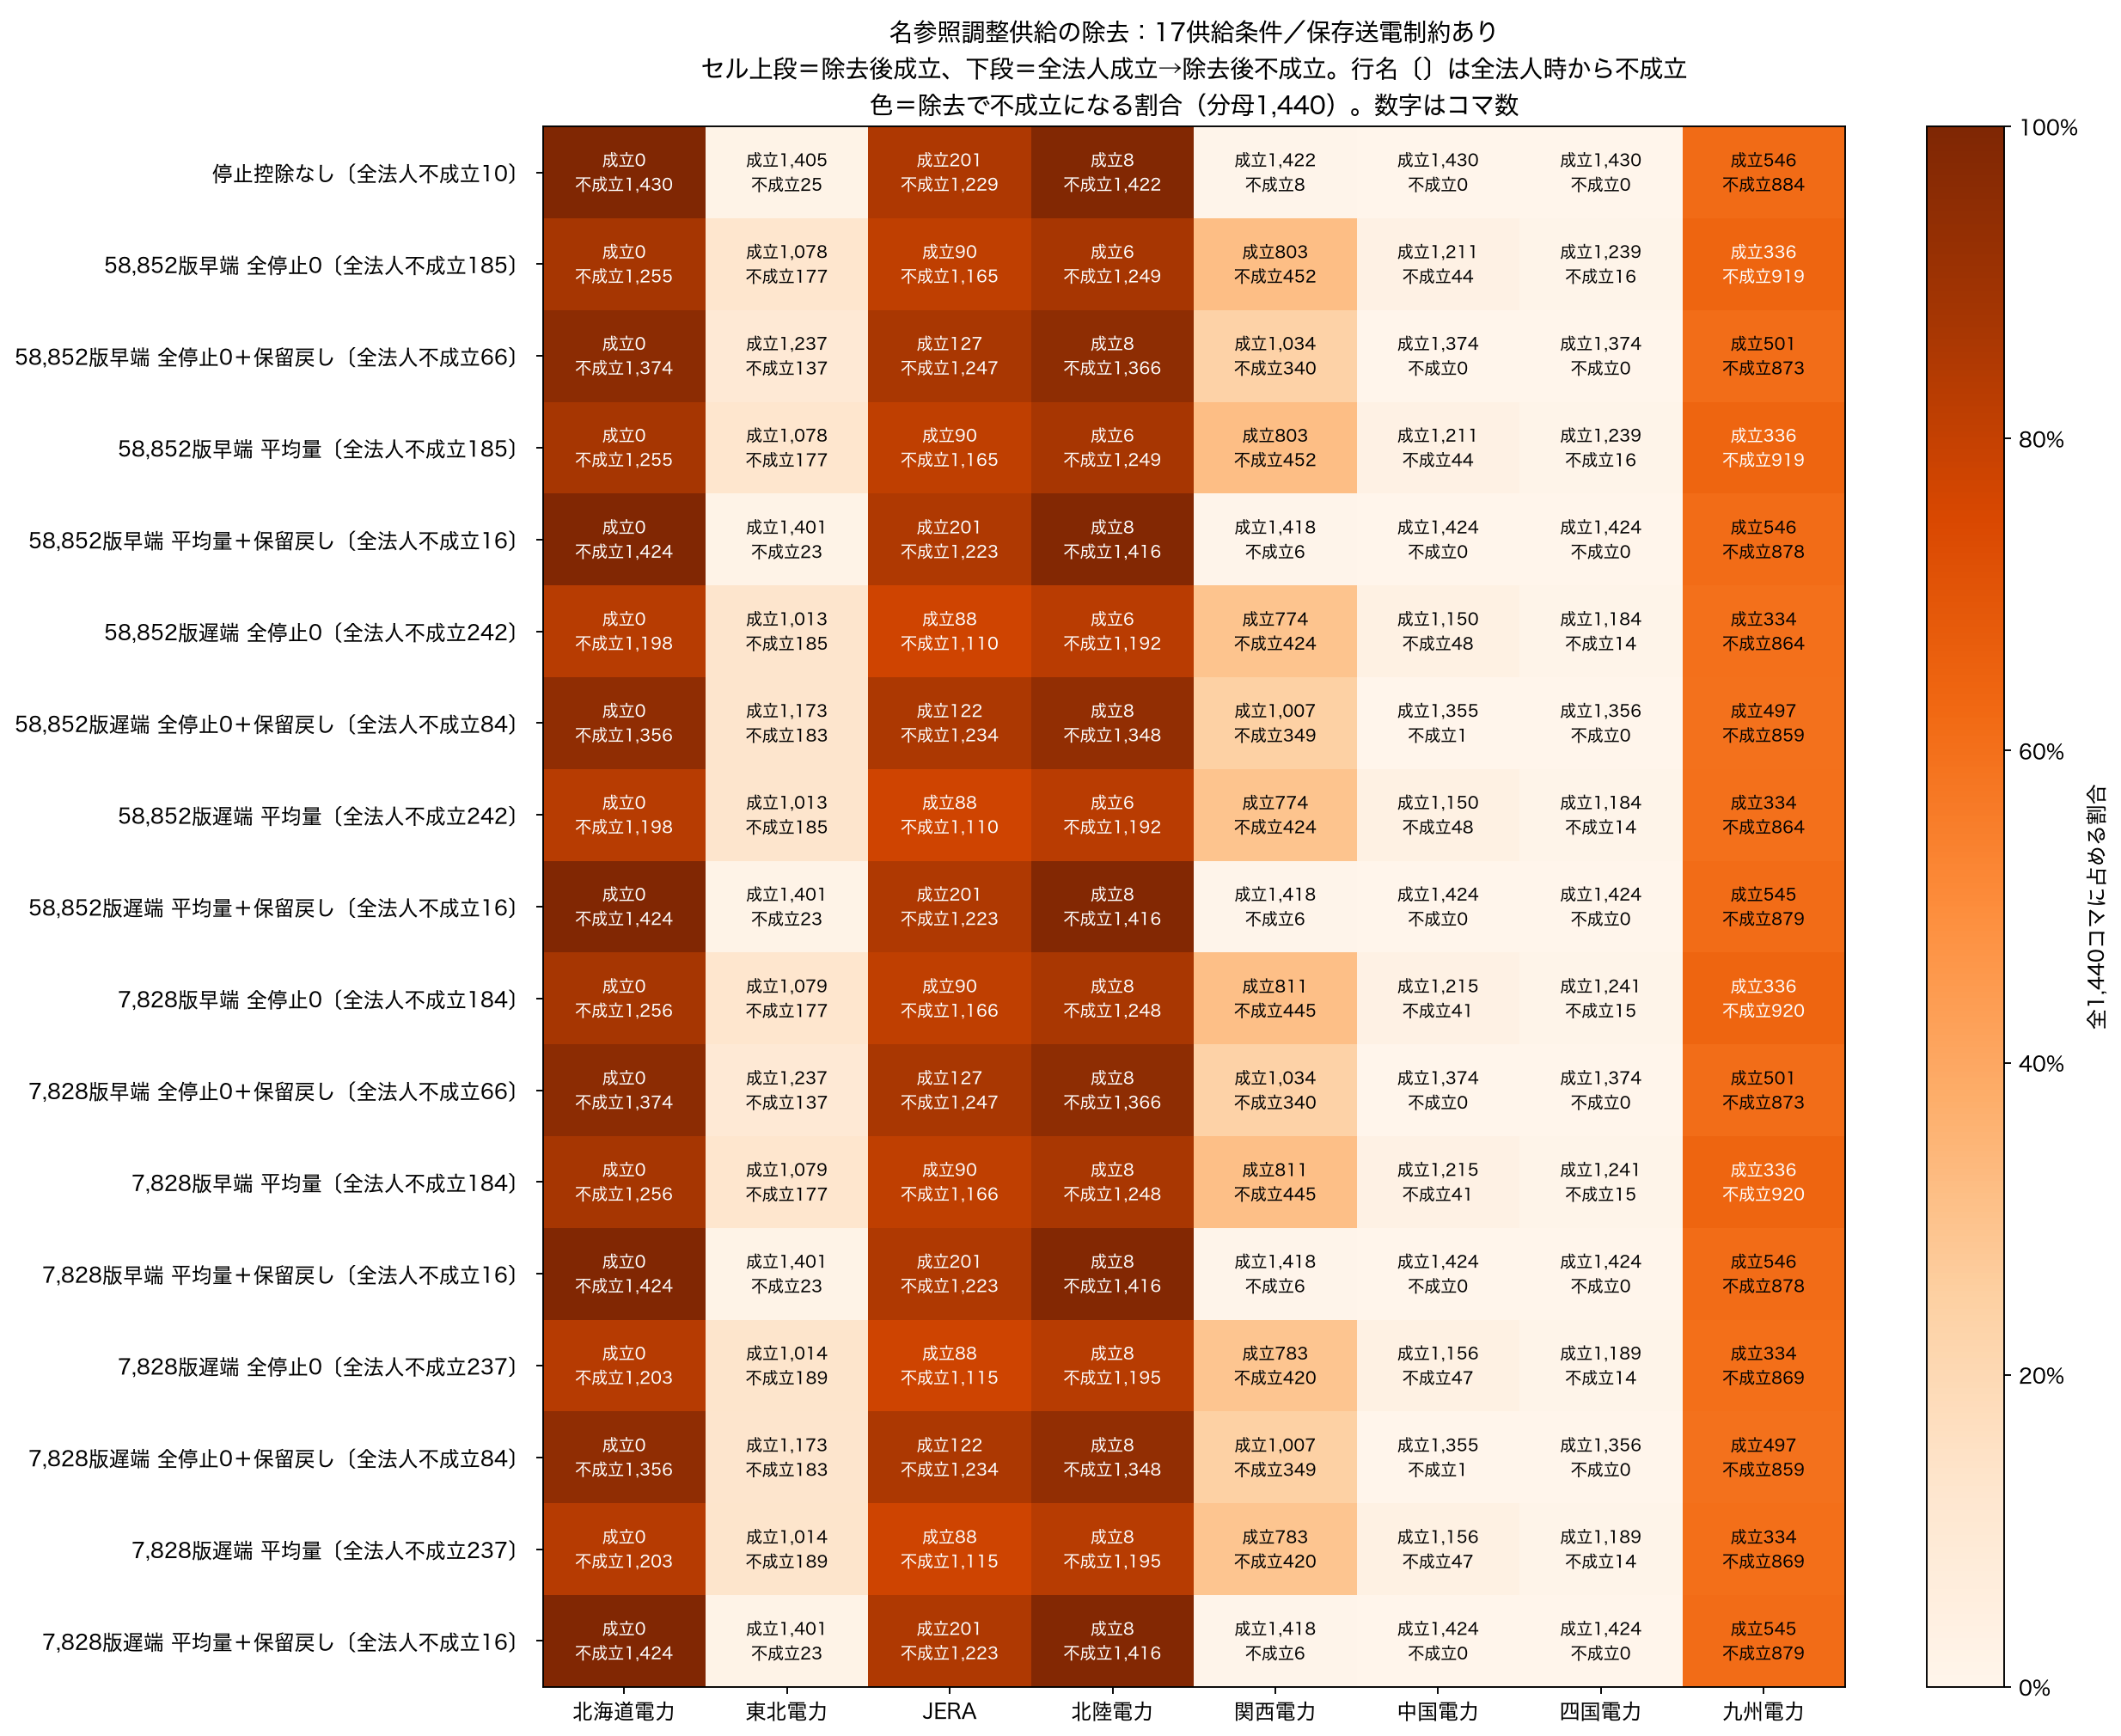

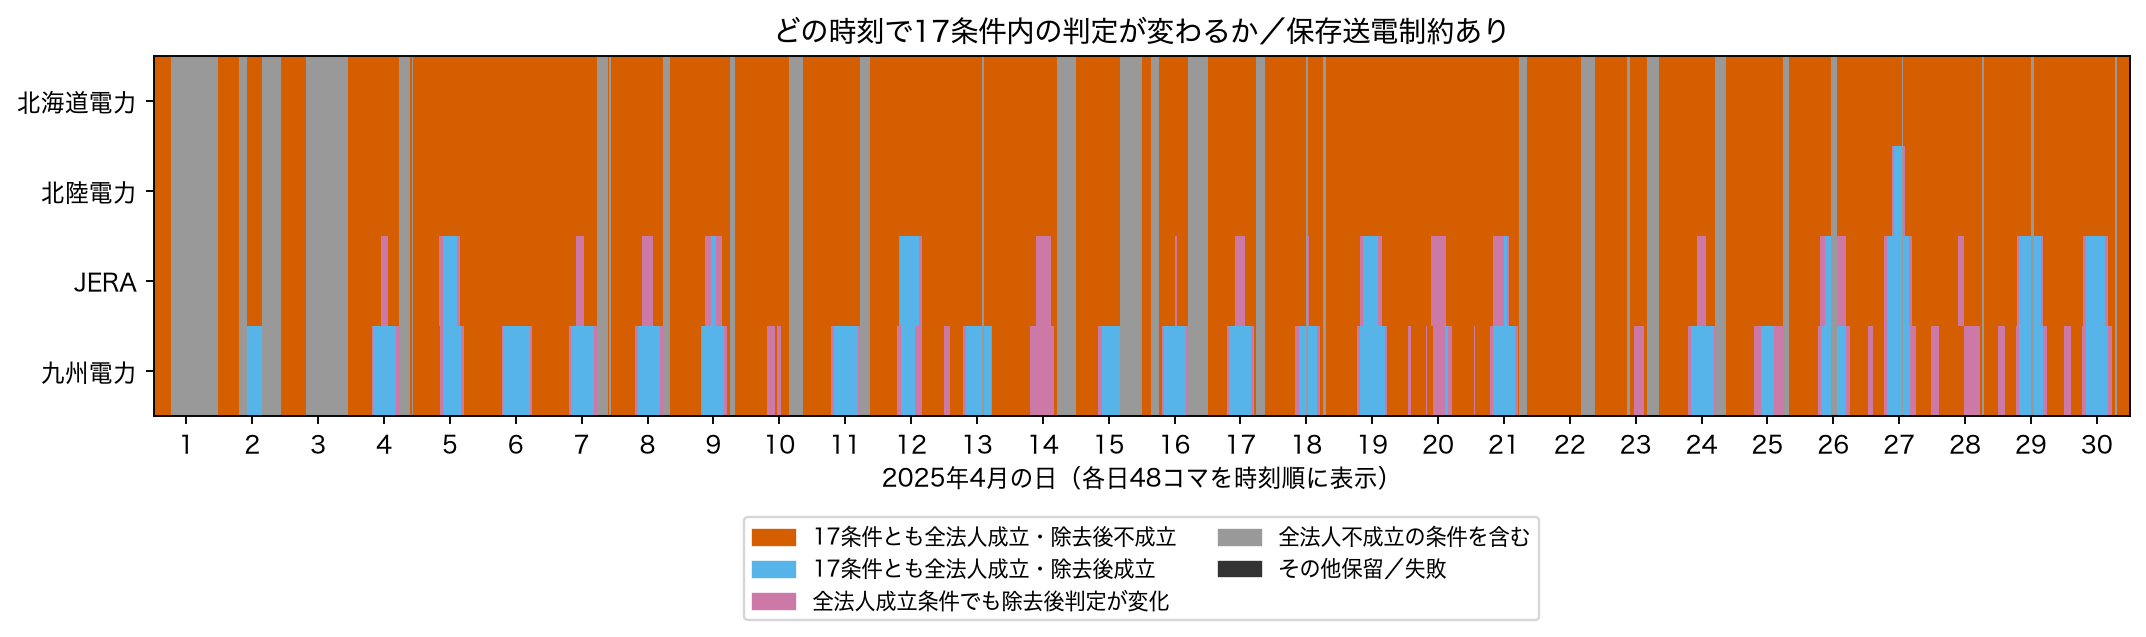

In [3]:
show("01_all17_removal_failure")
show("04_focus_time_states")

## 2．同じ時刻の停止ペア

元8条件と、対応する記録保留の追加控除なし8条件の対比較です。双方で全法人成立する範囲の除去後判定変化と、全法人時の判定自体の変化を分けます。範囲は全時刻です。

In [4]:
pairs = pd.read_csv(QA / "stop_pair_simultaneous_summary.csv")
display(pairs[pairs.network_scenario.eq("saved_plan_constraints")])

,original_scenario,network_scenario,entity_code,time_keys,both_baseline_feasible,removed_failure_to_feasible_comparable,baseline_became_feasible
8,58852_early__full_stop_zero,saved_plan_constraints,chugoku,1440,1255,44,119
9,58852_early__full_stop_zero,saved_plan_constraints,hokkaido,1440,1255,0,119
10,58852_early__full_stop_zero,saved_plan_constraints,hokuriku,1440,1255,2,119
11,58852_early__full_stop_zero,saved_plan_constraints,jera,1440,1255,37,119
12,58852_early__full_stop_zero,saved_plan_constraints,kansai,1440,1255,218,119
...,...,...,...,...,...,...,...
123,7828_late__mean_reduction,saved_plan_constraints,jera,1440,1203,113,221
124,7828_late__mean_reduction,saved_plan_constraints,kansai,1440,1203,420,221
125,7828_late__mean_reduction,saved_plan_constraints,kyushu,1440,1203,178,221
126,7828_late__mean_reduction,saved_plan_constraints,shikoku,1440,1203,14,221


## 3．送電包絡を一組ずつ解除する

9地域の接続・需要・固定R・供給上限を残し、上下包絡だけを外します。図は元から全法人成立の1,430コマ内の変化。全1,440コマ・全statusも保存します。単独解除で変わらなくても重要でないとは言えません。

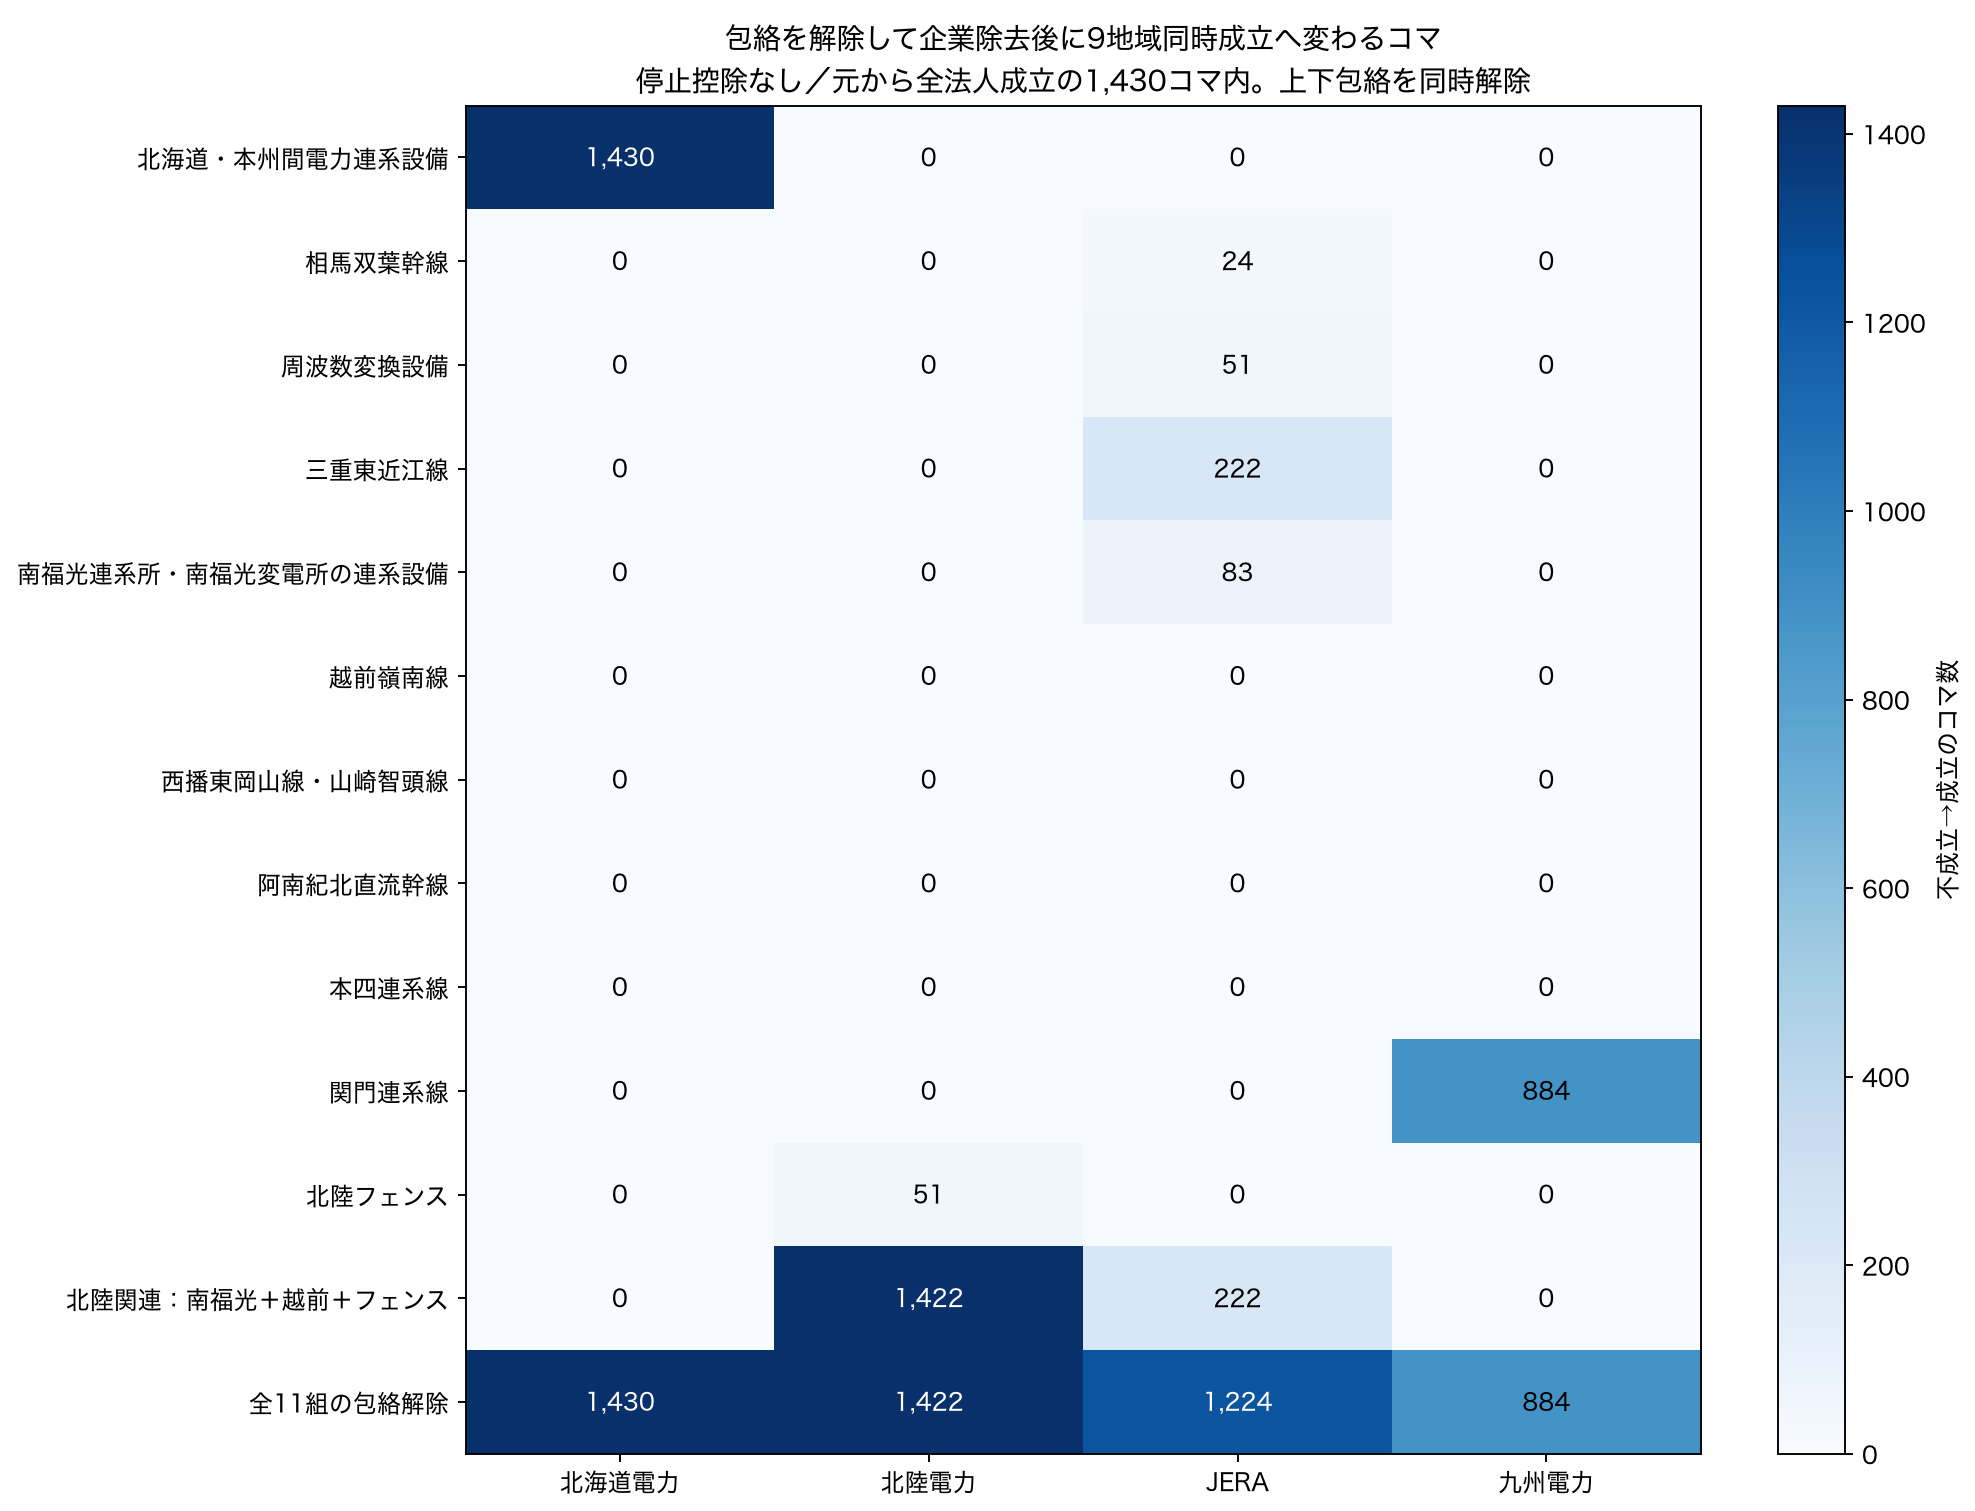

,release_case,entity_code,time_keys,base_all_firms_feasible,after_all_firms_feasible,removed_feasible_before,removed_feasible_after,removed_failure_to_feasible,recovered_where_baseline_already_feasible
0,saved_all,hokkaido,1440,1430,1430,0,0,0,0
1,saved_all,hokuriku,1440,1430,1430,8,8,0,0
2,saved_all,jera,1440,1430,1430,201,201,0,0
3,saved_all,kyushu,1440,1430,1430,546,546,0,0
4,release_01,hokkaido,1440,1430,1430,0,1430,1430,1430
5,release_01,hokuriku,1440,1430,1430,8,8,0,0
6,release_01,jera,1440,1430,1430,201,201,0,0
7,release_01,kyushu,1440,1430,1430,546,546,0,0
8,release_02,hokkaido,1440,1430,1430,0,0,0,0
9,release_02,hokuriku,1440,1430,1430,8,8,0,0


,release_case,target_area,time_keys,common_valid,newly_valid,lost_valid,lambda_difference_median,lambda_difference_max,changed_common,median_before_common,median_after_common
0,saved_all,中部,1440,423,0,0,0.000000,0.000000,0,0.971023,0.971023
1,saved_all,九州,1440,1198,0,0,0.000000,0.000000,0,0.812100,0.812100
2,saved_all,北海道,1440,1430,0,0,0.000000,0.000000,0,0.203504,0.203504
3,saved_all,北陸,1440,1430,0,0,0.000000,0.000000,0,0.451382,0.451382
4,saved_all,東京,1440,225,0,0,0.000000,0.000000,0,1.343099,1.343099
...,...,...,...,...,...,...,...,...,...,...,...
65,release_all,中部,1440,423,1017,0,7.773875,47.810467,423,0.971023,8.852475
66,release_all,九州,1440,1198,0,0,13.063043,34993.485000,1198,0.812100,13.878404
67,release_all,北海道,1440,1430,10,0,27.628245,136.702601,1430,0.203504,27.851923
68,release_all,北陸,1440,1430,10,0,26.278407,113.062582,1430,0.451382,26.722703


In [5]:
show("03_constraint_release")
display(pd.read_csv(QA / "release_simultaneous_summary.csv"))
display(pd.read_csv(QA / "release_multiplier_summary.csv"))

## 4．供給範囲の数値変化と、情報保留による集合縮小

他者上限の低下を、保留を戻しても残る数値シナリオ差と、記録保留の集合差へ分解します。ここで容量値が分かることと、利用可能性が確認されたことは別です。元台帳にも容量がない設備は0にしません。容量coverageの全国分母は確定していないので割合にしません。

In [6]:
display(pd.read_csv(QA / "supply_decomposition_summary.csv", header=[0, 1], index_col=[0, 1]))
display(pd.read_csv(QA / "supply_scope_summary.csv"))
display(pd.read_csv(QA / "focus_slack_diagnosis_counts.csv"))

known_numeric_scenario_reduction_other_mw  \
                                                                              min   
supply_trial_scenario       entity_code                                             
58852_early__full_stop_zero hokkaido                                    26128.875   
                            hokuriku                                    25853.875   
                            jera                                        18237.975   
                            kyushu                                      25288.875   
58852_early__mean_reduction hokkaido                                      818.800   
                            hokuriku                                      918.800   
                            jera                                          918.800   
                            kyushu                                        918.800   
58852_late__full_stop_zero  hokkaido                                    27149.875   
                            hokuriku                                    26874.875   
                            jera                                        19258.975   
                            kyushu                                      26309.875   
58852_late__mean_reduction  hokkaido                                     2038.730   
                            hokuriku                                     1939.480   
                            jera                                         1506.875   
                            kyushu                                       1896.480   
7828_early__full_stop_zero  hokkaido                                    27128.875   
                            hokuriku                                    26953.875   
                            jera                                        19337.975   
                            kyushu                                      26388.875   
7828_early__mean_reduction  hokkaido                                      818.800   
                            hokuriku                                      918.800   
                            jera                                          918.800   
                            kyushu                                        918.800   
7828_late__full_stop_zero   hokkaido                                    27392.751   
                            hokuriku                                    27217.751   
                            jera                                        19601.851   
                            kyushu                                      26652.751   
7828_late__mean_reduction   hokkaido                                     2038.730   
                            hokuriku                                     1939.480   
                            jera                                         1506.875   
                            kyushu                                       1896.480   

                                                                  \
                                                 mean        max   
supply_trial_scenario       entity_code                            
58852_early__full_stop_zero hokkaido     33689.415078  40322.255   
                            hokuriku     33433.826050  40397.255   
                            jera         23652.317300  27935.881   
                            kyushu       32384.046467  39802.255   
58852_early__mean_reduction hokkaido      2775.211564   4370.184   
                            hokuriku      2786.482258   4165.484   
                            jera          2507.778231   3287.130   
                            kyushu        2273.002675   3607.784   
58852_late__full_stop_zero  hokkaido     35553.603984  42714.413   
                            hokuriku     35258.590165  42789.413   
                            jera         24877.401484  29107.405   
                            kyushu       34170.141484  41964.413   
58852_late__mean_reduction  hokkaido      31

,supply_trial_scenario,area,time_keys,outside_count_min,outside_count_max,unknown_raw_capacity_labels_max,known_outside_raw_snapshot_mw_max,record_held_count_max
0,58852_early__full_stop_zero,中国,1440,7,15,0,4773.4,11
1,58852_early__full_stop_zero,中部,1440,16,19,12,2938.2,6
2,58852_early__full_stop_zero,九州,1440,8,11,1,4321.4,9
3,58852_early__full_stop_zero,北海道,1440,6,7,0,1487.0,5
4,58852_early__full_stop_zero,北陸,1440,3,4,1,474.0,3
...,...,...,...,...,...,...,...,...
148,reference_no_deduction,北陸,1440,1,1,1,NaN,0
149,reference_no_deduction,四国,1440,2,2,0,617.0,0
150,reference_no_deduction,東京,1440,31,31,29,600.0,0
151,reference_no_deduction,東北,1440,11,11,9,712.0,0


,supply_trial_scenario,entity_code,all_firms_status,diagnostic_kind,time_keys
0,58852_early__full_stop_zero,hokkaido,feasible,national_limited_upper_shortfall,1
1,58852_early__full_stop_zero,hokkaido,feasible,regional_delivery_restriction,1254
2,58852_early__full_stop_zero,hokkaido,infeasible,national_limited_upper_shortfall,79
3,58852_early__full_stop_zero,hokkaido,infeasible,regional_deficit_and_local_absorption,10
4,58852_early__full_stop_zero,hokkaido,infeasible,regional_delivery_restriction,96
...,...,...,...,...,...
316,reference_no_deduction,jera,feasible,regional_delivery_restriction,1224
317,reference_no_deduction,jera,infeasible,local_absorption_or_export_restriction,9
318,reference_no_deduction,jera,infeasible,regional_deficit_and_local_absorption,1
319,reference_no_deduction,kyushu,feasible,regional_delivery_restriction,884


## 5．代表時刻：2025-04-01 period1

規則は各法人の「17条件全てで全法人成立・除去後不成立の最初の時刻」。価格は使いません。4法人とも00:00〜00:30でした。

北海道：純需要3,067 MWに対し他者上限250＋北本逆向き包絡237＝487、差2,580 MW。北陸：3,027−486−700＝1,841 MW。九州：5,926−3,554−250＝2,122 MW。

JERA除去後は、東京・中部の純需要計41,878 MWに対し域内上限計19,557.97、外から入る境界包絡6,160、差16,160.03 MW。FCは2地域の内部なので外部供給へ重複加算しません。評価地域を統合したわけではありません。診断上の地域別過不足は実際の原因の所在地や一意な割当てではありません。

In [7]:
display(pd.read_csv(QA / "representative_selection.csv"))
display(pd.read_csv(QA / "representative_regional_account.csv"))
display(pd.read_csv(QA / "representative_constraints.csv"))

,entity_code,delivery_date,period,selection_rule,price_used,supply_trial_scenario,diagnostic_slack_sum_mw,diagnostic_residual_mw
0,hokkaido,2025-04-01,1,17条件全て全法人成立かつ除去後不成立の最初の時刻,False,reference_no_deduction,2580.00,0.000000e+00
1,hokuriku,2025-04-01,1,17条件全て全法人成立かつ除去後不成立の最初の時刻,False,reference_no_deduction,1841.00,0.000000e+00
2,jera,2025-04-01,1,17条件全て全法人成立かつ除去後不成立の最初の時刻,False,reference_no_deduction,16160.03,9.094947e-13
3,kyushu,2025-04-01,1,17条件全て全法人成立かつ除去後不成立の最初の時刻,False,reference_no_deduction,2122.00,9.094947e-13


,entity_code,delivery_date,period,area,demand_actual_mw,fixed_actual_R_mw,net_demand_mw,all_firms_known_upper_mw,removed_target_upper_mw,remaining_upper_mw,diagnostic_deficit_mw,diagnostic_surplus_mw
0,hokkaido,2025-04-01,1,北海道,3323.0,256.0,3067.0,5519.40,5269.4,250.00,2580.00,0.0
1,hokkaido,2025-04-01,1,東北,8415.0,932.0,7483.0,17127.00,0.0,17127.00,0.00,0.0
2,hokkaido,2025-04-01,1,東京,28819.0,101.0,28718.0,36638.67,0.0,36638.67,0.00,0.0
3,hokkaido,2025-04-01,1,中部,13194.0,34.0,13160.0,19260.20,0.0,19260.20,0.00,0.0
4,hokkaido,2025-04-01,1,北陸,3034.0,7.0,3027.0,5438.70,0.0,5438.70,0.00,0.0
5,hokkaido,2025-04-01,1,関西,13456.0,4890.0,8566.0,20709.00,0.0,20709.00,0.00,0.0
6,hokkaido,2025-04-01,1,中国,6053.0,824.0,5229.0,10451.00,0.0,10451.00,0.00,0.0
7,hokkaido,2025-04-01,1,四国,2540.0,882.0,1658.0,6400.00,0.0,6400.00,0.00,0.0
8,hokkaido,2025-04-01,1,九州,8996.0,3070.0,5926.0,13889.00,0.0,13889.00,0.00,0.0
9,hokuriku,2025-04-01,1,北海道,3323.0,256.0,3067.0,5519.40,0.0,5519.40,0.00,0.0


,entity_code,delivery_date,period,constraint_name,coefficients_json,lower_mw,upper_mw
0,hokkaido,2025-04-01,1,北海道・本州間電力連系設備,"[1, 0, 0, 0, 0, 0, 0, 0, 0, 0]",-237.000,680.0
1,hokkaido,2025-04-01,1,相馬双葉幹線,"[0, 1, 0, 0, 0, 0, 0, 0, 0, 0]",-2360.000,3860.0
2,hokkaido,2025-04-01,1,周波数変換設備,"[0, 0, 1, 0, 0, 0, 0, 0, 0, 0]",-750.000,750.0
3,hokkaido,2025-04-01,1,三重東近江線,"[0, 0, 0, 1, 0, 0, 0, 0, 0, 0]",-2000.000,950.0
4,hokkaido,2025-04-01,1,南福光連系所・南福光変電所の連系設備,"[0, 0, 0, 0, 1, 0, 0, 0, 0, 0]",-300.000,300.0
5,hokkaido,2025-04-01,1,越前嶺南線,"[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]",-700.000,1896.0
6,hokkaido,2025-04-01,1,西播東岡山線・山崎智頭線,"[0, 0, 0, 0, 0, 0, 1, 0, 0, 0]",-4634.845,3240.0
7,hokkaido,2025-04-01,1,阿南紀北直流幹線,"[0, 0, 0, 0, 0, 0, 0, 1, 0, 0]",-140.000,0.0
8,hokkaido,2025-04-01,1,本四連系線,"[0, 0, 0, 0, 0, 0, 0, 0, 1, 0]",0.000,0.0
9,hokkaido,2025-04-01,1,関門連系線,"[0, 0, 0, 0, 0, 0, 0, 0, 0, 1]",-1830.000,250.0


## 6．全時刻から任意の条件・法人を確認する

下の選択は閲覧用です。研究baselineの選択ではありません。

In [8]:
all_times = pd.read_parquet(OUT / "condition_consistency_all_times.parquet")
selected_entity = "jera"
selected_network = "saved_plan_constraints"
selected = all_times[
    all_times.entity_code.eq(selected_entity) & all_times.network_scenario.eq(selected_network)
]
assert len(selected) == 1440
display(selected.head(48))
print("この選択の全時刻:", len(selected))

,network_scenario,entity_code,delivery_date,period,consistency_state,baseline_feasible_conditions,removed_feasible_comparable_conditions,removed_infeasible_comparable_conditions,removed_varies_among_comparable,all17_baseline_infeasible
2,saved_plan_constraints,jera,2025-04-01,1,all17_base_feasible_removed_infeasible,17,0,17,False,False
18,saved_plan_constraints,jera,2025-04-01,2,all17_base_feasible_removed_infeasible,17,0,17,False,False
34,saved_plan_constraints,jera,2025-04-01,3,all17_base_feasible_removed_infeasible,17,0,17,False,False
50,saved_plan_constraints,jera,2025-04-01,4,all17_base_feasible_removed_infeasible,17,0,17,False,False
66,saved_plan_constraints,jera,2025-04-01,5,all17_base_feasible_removed_infeasible,17,0,17,False,False
82,saved_plan_constraints,jera,2025-04-01,6,all17_base_feasible_removed_infeasible,17,0,17,False,False
98,saved_plan_constraints,jera,2025-04-01,7,all17_base_feasible_removed_infeasible,17,0,17,False,False
114,saved_plan_constraints,jera,2025-04-01,8,all17_base_feasible_removed_infeasible,17,0,17,False,False
130,saved_plan_constraints,jera,2025-04-01,9,all17_base_feasible_removed_infeasible,17,0,17,False,False
146,saved_plan_constraints,jera,2025-04-01,10,all17_base_feasible_removed_infeasible,17,0,17,False,False


この選択の全時刻: 1440


## 7．別出力先への再構築

既定は保存版の閲覧です。再構築は17条件集計・11組解除・重点4法人の過不足診断を含み、数分かかります。既存版を上書きせず新しい時刻付きディレクトリへ出力します。

In [9]:
REBUILD = False
if REBUILD:
    from datetime import datetime
    from zoneinfo import ZoneInfo

    from scripts.diagnose_april_constraint_slacks import run as run_slacks
    from scripts.diagnose_april_constraints import run
    from src.april_constraint_figures import render

    stamp = datetime.now(ZoneInfo("Asia/Tokyo")).strftime("%Y%m%dT%H%M%S")
    new_output = ROOT / "data/interim/occto/april_constraint_diagnosis" / (stamp + "_reproduction")
    new_report = new_output / "review"
    run(ROOT, new_output, new_report)
    run_slacks(ROOT, new_output, new_report)
    render(new_output, new_report)
    print("再構築先:", new_output)
else:
    import pyarrow.parquet as pq

    for path in sorted(OUT.glob("*.parquet")):
        print(path.name, f"{pq.read_metadata(path).num_rows:,}行")

condition_consistency_all_times.parquet 23,040行
constraint_release_multipliers_all_times.parquet 100,800行
constraint_release_simultaneous_all_times.parquet 80,640行
focus_diagnostic_slacks_all_infeasible.parquet 88,173行
focus_regional_supply_scope_all_times.parquet 881,280行
paired_simultaneous_all_times.parquet 184,320行
simultaneous_input_scope_diagnosis.parquet 391,680行
supply_scope_decomposition_all_times.parquet 414,720行
